In [1]:
import os
import glob
import pandas as pd
import numpy as np

import matplotlib as mpl
import matplotlib.pyplot as plt

In [2]:
FOLDER = "."

excel_files = glob.glob(os.path.join(FOLDER, "*.xlsx"))

print(f"Found {len(excel_files)} Excel file:")
for f in excel_files:
    print(" -", os.path.basename(f))

all_data = {}

for fpath in excel_files:
    key = os.path.splitext(os.path.basename(fpath))[0]
    all_data[key] = pd.read_excel(fpath, sheet_name=None)
    print(f"[OK] {key} -> sheets: {list(all_data[key].keys())}")

# Validation class 1 — Thermo-Hydraulic Validation (THV).
DHN_THV_3G_R_S_BASE = all_data["DHN_THV_3G_R_S_BASE_results"]
DHN_THV_3G_L_S_BASE = all_data["DHN_THV_3G_L_S_BASE_results"]
DHN_THV_3G_M_S_BASE = all_data["DHN_THV_3G_M_S_BASE_results"]

# Validation class 2 — Technology Assessment (TG).
DHN_TG_3G_M_M_BASE = all_data["DHN_TG_3G_M_M_BASE_results"]
DHN_TG_4G_M_M_BASE = all_data["DHN_TG_4G_M_M_BASE_results"]
DHN_TG_5G_M_M_BASE = all_data["DHN_TG_5G_M_M_BASE_results"]

# Validation class 3 — Computational Scalability (CS).
DHN_CS_3G_M_L_BASE = all_data["DHN_CS_3G_M_L_BASE_results"]

networks = {
    "DHN_THV_3G_R_S_BASE": DHN_THV_3G_R_S_BASE,
    "DHN_THV_3G_L_S_BASE": DHN_THV_3G_L_S_BASE,
    "DHN_THV_3G_M_S_BASE": DHN_THV_3G_M_S_BASE,
    "DHN_TG_3G_M_M_BASE":  DHN_TG_3G_M_M_BASE,
    "DHN_TG_4G_M_M_BASE":  DHN_TG_4G_M_M_BASE,
    "DHN_TG_5G_M_M_BASE":  DHN_TG_5G_M_M_BASE,
    "DHN_CS_3G_M_L_BASE":  DHN_CS_3G_M_L_BASE,
}


LONG_FORMAT_SHEETS = {"convergence_traj"}

for net_name, sheets in networks.items():
    for sheet_name, df in sheets.items():
        if sheet_name in LONG_FORMAT_SHEETS:
            continue
        first_col = df.columns[0]
        df = df.rename(columns={first_col: "timestep"})
        df = df.set_index("timestep")
        sheets[sheet_name] = df

Found 7 Excel file:
 - DHN_CS_3G_M_L_BASE_results.xlsx
 - DHN_TG_3G_M_M_BASE_results.xlsx
 - DHN_TG_4G_M_M_BASE_results.xlsx
 - DHN_TG_5G_M_M_BASE_results.xlsx
 - DHN_THV_3G_L_S_BASE_results.xlsx
 - DHN_THV_3G_M_S_BASE_results.xlsx
 - DHN_THV_3G_R_S_BASE_results.xlsx
[OK] DHN_CS_3G_M_L_BASE_results -> sheets: ['sub_T_supply_degC', 'sub_T_return_degC', 'sub_dT_K', 'sub_mdot_kgs', 'sub_Q_W', 'source', 'pipe_s_dp_Pa', 'pipe_r_dp_Pa', 'pipe_s_mdot_kgs', 'pipe_s_T_out_degC', 'pipe_r_T_out_degC', 'pipe_s_Qloss_W', 'pipe_r_Qloss_W', 'junction_T_degC', 'energy_balance']
[OK] DHN_TG_3G_M_M_BASE_results -> sheets: ['sub_T_supply_degC', 'sub_T_return_degC', 'sub_dT_K', 'sub_mdot_kgs', 'sub_Q_W', 'source', 'pipe_s_dp_Pa', 'pipe_r_dp_Pa', 'pipe_s_mdot_kgs', 'pipe_s_T_out_degC', 'pipe_r_T_out_degC', 'pipe_s_Qloss_W', 'pipe_r_Qloss_W', 'junction_T_degC', 'energy_balance']
[OK] DHN_TG_4G_M_M_BASE_results -> sheets: ['sub_T_supply_degC', 'sub_T_return_degC', 'sub_dT_K', 'sub_mdot_kgs', 'sub_Q_W', 'src_

In [3]:
THV_NETWORKS = {
    "Radial": DHN_THV_3G_R_S_BASE,
    "Ring":   DHN_THV_3G_L_S_BASE,
    "Mesh":   DHN_THV_3G_M_S_BASE,
}

TG_NETWORKS = {
    "3G":     DHN_TG_3G_M_M_BASE,
    "4G":     DHN_TG_4G_M_M_BASE,
    "5G":     DHN_TG_5G_M_M_BASE,
}

CS_NETWORKS = {
    "Small":  DHN_THV_3G_M_S_BASE,
    "Medium": DHN_TG_3G_M_M_BASE,
    "Large":  DHN_CS_3G_M_L_BASE,
}

In [4]:
mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    print(f"[SAVED] {name}.png")

Using ARCHETYPES_DIR = C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\archetypes
[SAVED] THV_supply_flow_direction.png


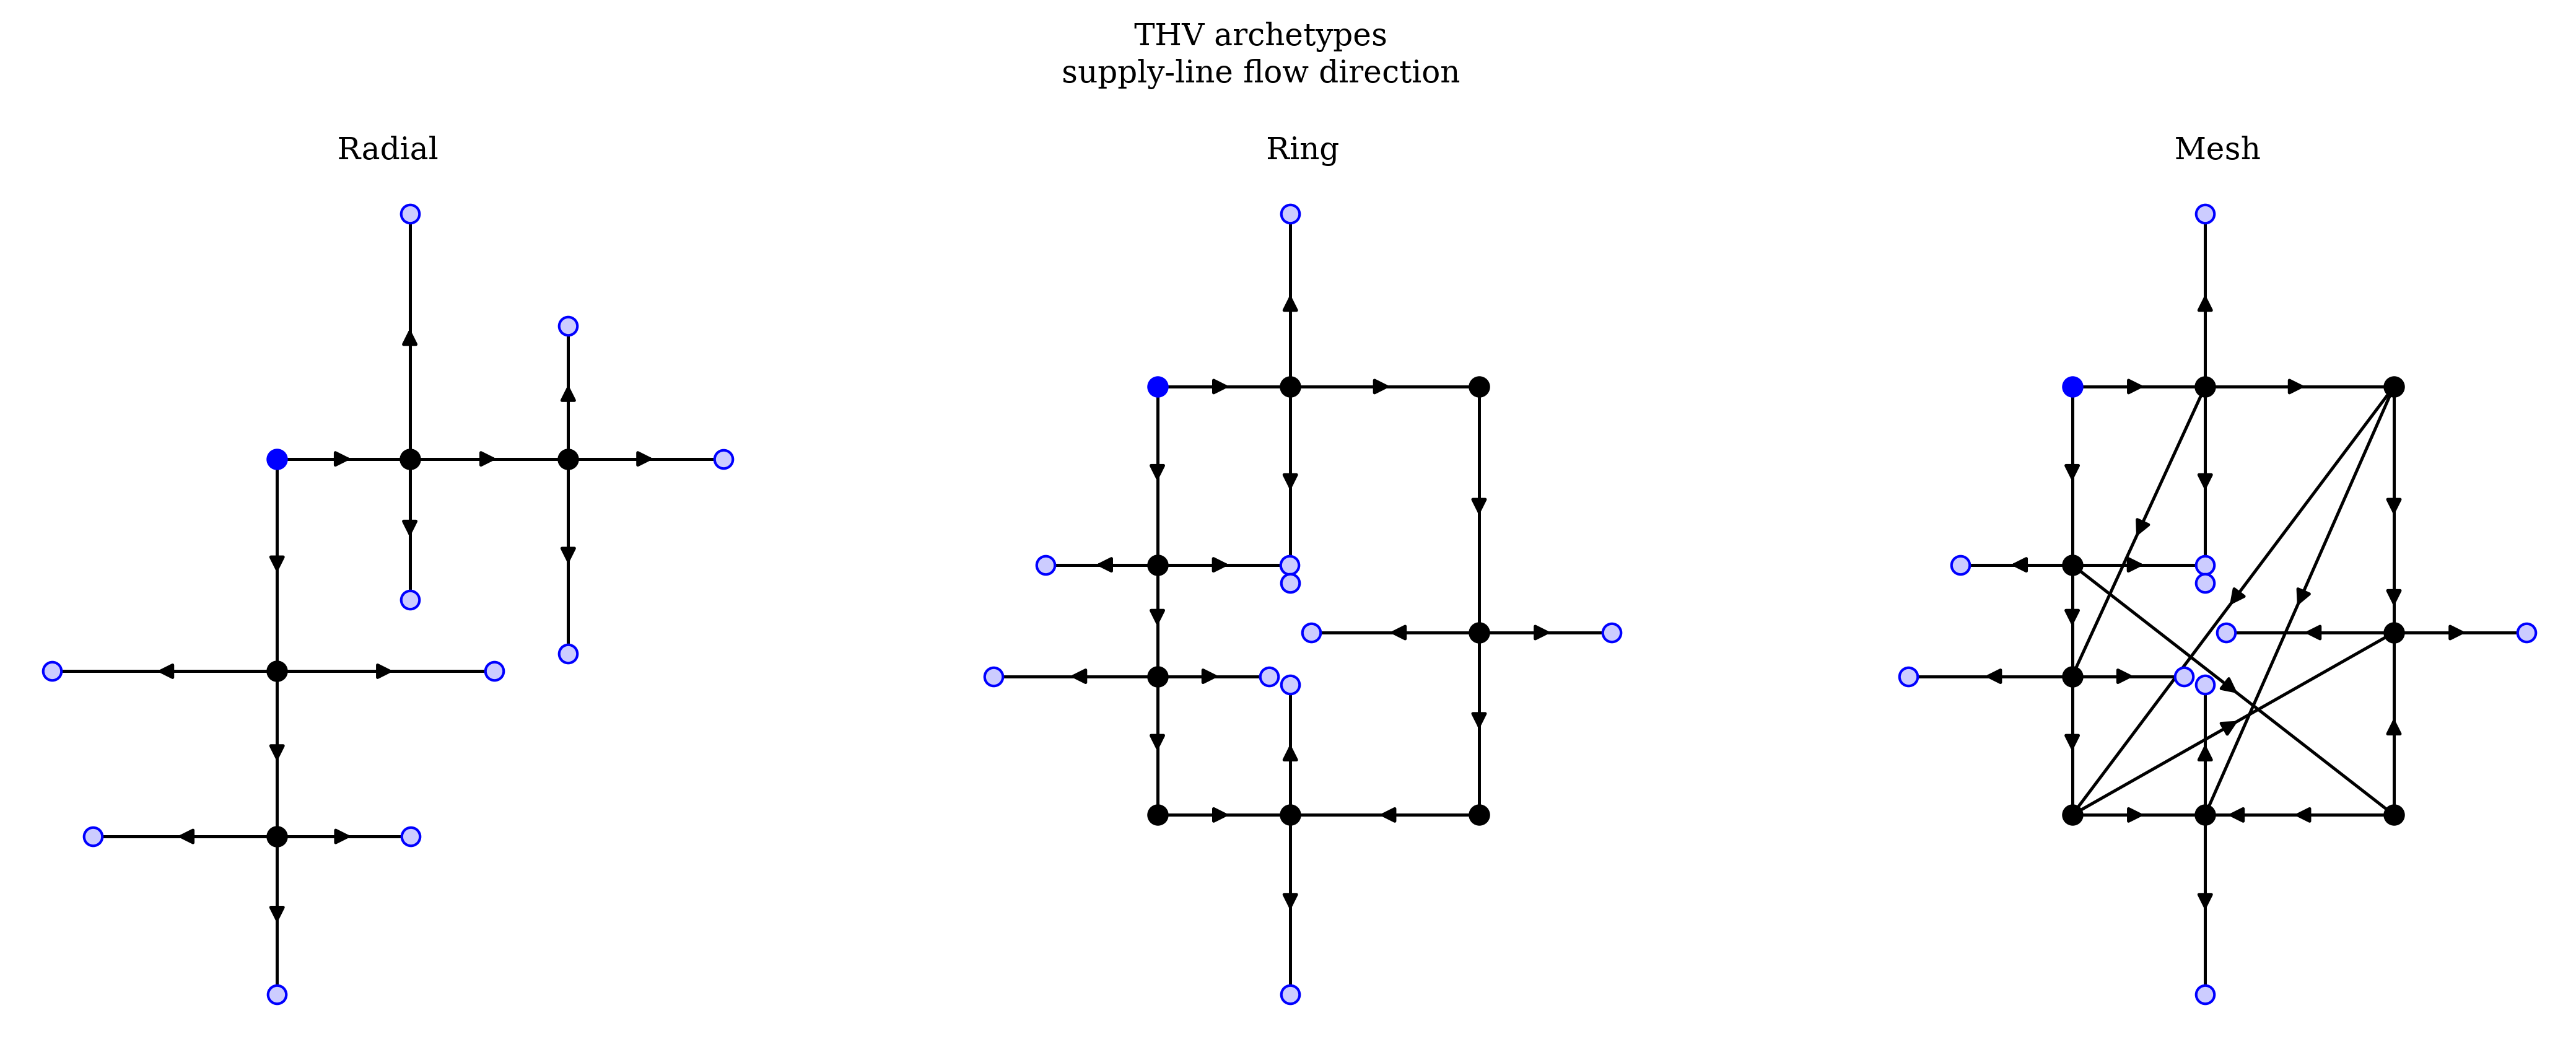

In [16]:
# ---------------------------------------------------------------------------
# CELL 5 — THV: network graph FLOW DIRECTION
# ---------------------------------------------------------------------------
import glob
from matplotlib.patches import FancyArrowPatch

def find_archetypes_dir(anchor_network="DHN_THV_3G_R_S_BASE", max_up=5):
    cur = os.path.abspath(".")
    for _ in range(max_up + 1):
        hits = glob.glob(os.path.join(cur, "**", anchor_network, "nodes.csv"),
                          recursive=True)
        if hits:
            return os.path.dirname(os.path.dirname(hits[0]))
        cur = os.path.dirname(cur)
    return None

ARCHETYPES_DIR = find_archetypes_dir()
if ARCHETYPES_DIR is None:
    raise FileNotFoundError(
        "Could not locate the 'archetypes' folder automatically. Set "
        "ARCHETYPES_DIR manually, e.g.:\n"
        "  ARCHETYPES_DIR = r'C:\\path\\to\\archetypes_generation\\archetypes'"
    )
print("Using ARCHETYPES_DIR =", ARCHETYPES_DIR)

THV_ARCHETYPE_NAMES = {
    "Radial": "DHN_THV_3G_R_S_BASE",
    "Ring":   "DHN_THV_3G_L_S_BASE",
    "Mesh":   "DHN_THV_3G_M_S_BASE",
}

NODE_STYLE = {
    # type       : (facecolor,  edgecolor, lw)
    "source"     : ("blue",     "blue",    1.2),
    "junction"   : ("black",    "black",   1.2),
    "substation" : ("#CCCCFF",  "blue",    1.0),
}

PIPE_COLOR = "black"
PIPE_LW    = 1.2
ARROW_COLOR = "black"

def load_topology(net_name):
    base = os.path.join(ARCHETYPES_DIR, net_name)
    nodes_df = pd.read_csv(os.path.join(base, "nodes.csv"))
    pipes_df = pd.read_csv(os.path.join(base, "pipes.csv"))
    pos   = {r.node_id: (r.x_m, r.y_m) for r in nodes_df.itertuples()}
    ntype = {r.node_id: r.node_type   for r in nodes_df.itertuples()}
    return pos, ntype, pipes_df

def match_pipe_id(u, v, mdot_index):
    for cand, sign in ((f"{u}_{v}_s", 1), (f"{v}_{u}_s", -1)):
        if cand in mdot_index:
            return cand, sign
    return None, None

supply_mdot_by_network = {}
for label, net_name in THV_ARCHETYPE_NAMES.items():
    supply_mdot_df = THV_NETWORKS[label]["pipe_s_mdot_kgs"]
    supply_mdot_by_network[label] = supply_mdot_df.mean(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (label, net_name) in zip(axes, THV_ARCHETYPE_NAMES.items()):
    pos, ntype, pipes_df = load_topology(net_name)
    mdot = supply_mdot_by_network[label]
    mdot_index = set(mdot.index)

    n_matched, n_missed = 0, 0

    for row in pipes_df.itertuples():
        u, v = row.from_node, row.to_node
        col, sign = match_pipe_id(u, v, mdot_index)
        if col is None:
            n_missed += 1
            continue
        m = mdot[col] * sign
        n_matched += 1

        x1, y1 = pos[u]
        x2, y2 = pos[v]

        # --- pipe as a plain line ---
        ax.plot([x1, x2], [-y1, -y2], color=PIPE_COLOR, lw=PIPE_LW, zorder=2)

        # --- direction arrow: u->v if m>=0, else v->u ---
        xm, ym = (x1 + x2) / 2, -(y1 + y2) / 2
        dx, dy = (x2 - x1), -(y2 - y1)
        length = np.hypot(dx, dy)
        if length == 0:
            continue
        ux, uy = dx / length, dy / length
        if m < 0:
            ux, uy = -ux, -uy
        arrow_len = min(20, length * 0.25)
        ax.add_patch(FancyArrowPatch(
            (xm - ux * arrow_len / 2, ym - uy * arrow_len / 2),
            (xm + ux * arrow_len / 2, ym + uy * arrow_len / 2),
            arrowstyle="-|>", mutation_scale=12,
            color=ARROW_COLOR, lw=1.2, zorder=4,
        ))

    for nid, (x, y) in pos.items():
        fc, ec, lw = NODE_STYLE[ntype[nid]]
        ax.scatter(x, -y, s=50, color=fc, edgecolor=ec, linewidth=lw, zorder=3)

    ax.set_title(label, fontsize=12)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_frame_on(False)
    ax.autoscale()

fig.suptitle("THV archetypes\nsupply-line flow direction", fontsize=12, y=1.02)

save_fig(fig, "THV_supply_flow_direction")
plt.show()

[SAVED] THV_solver_convergence.png


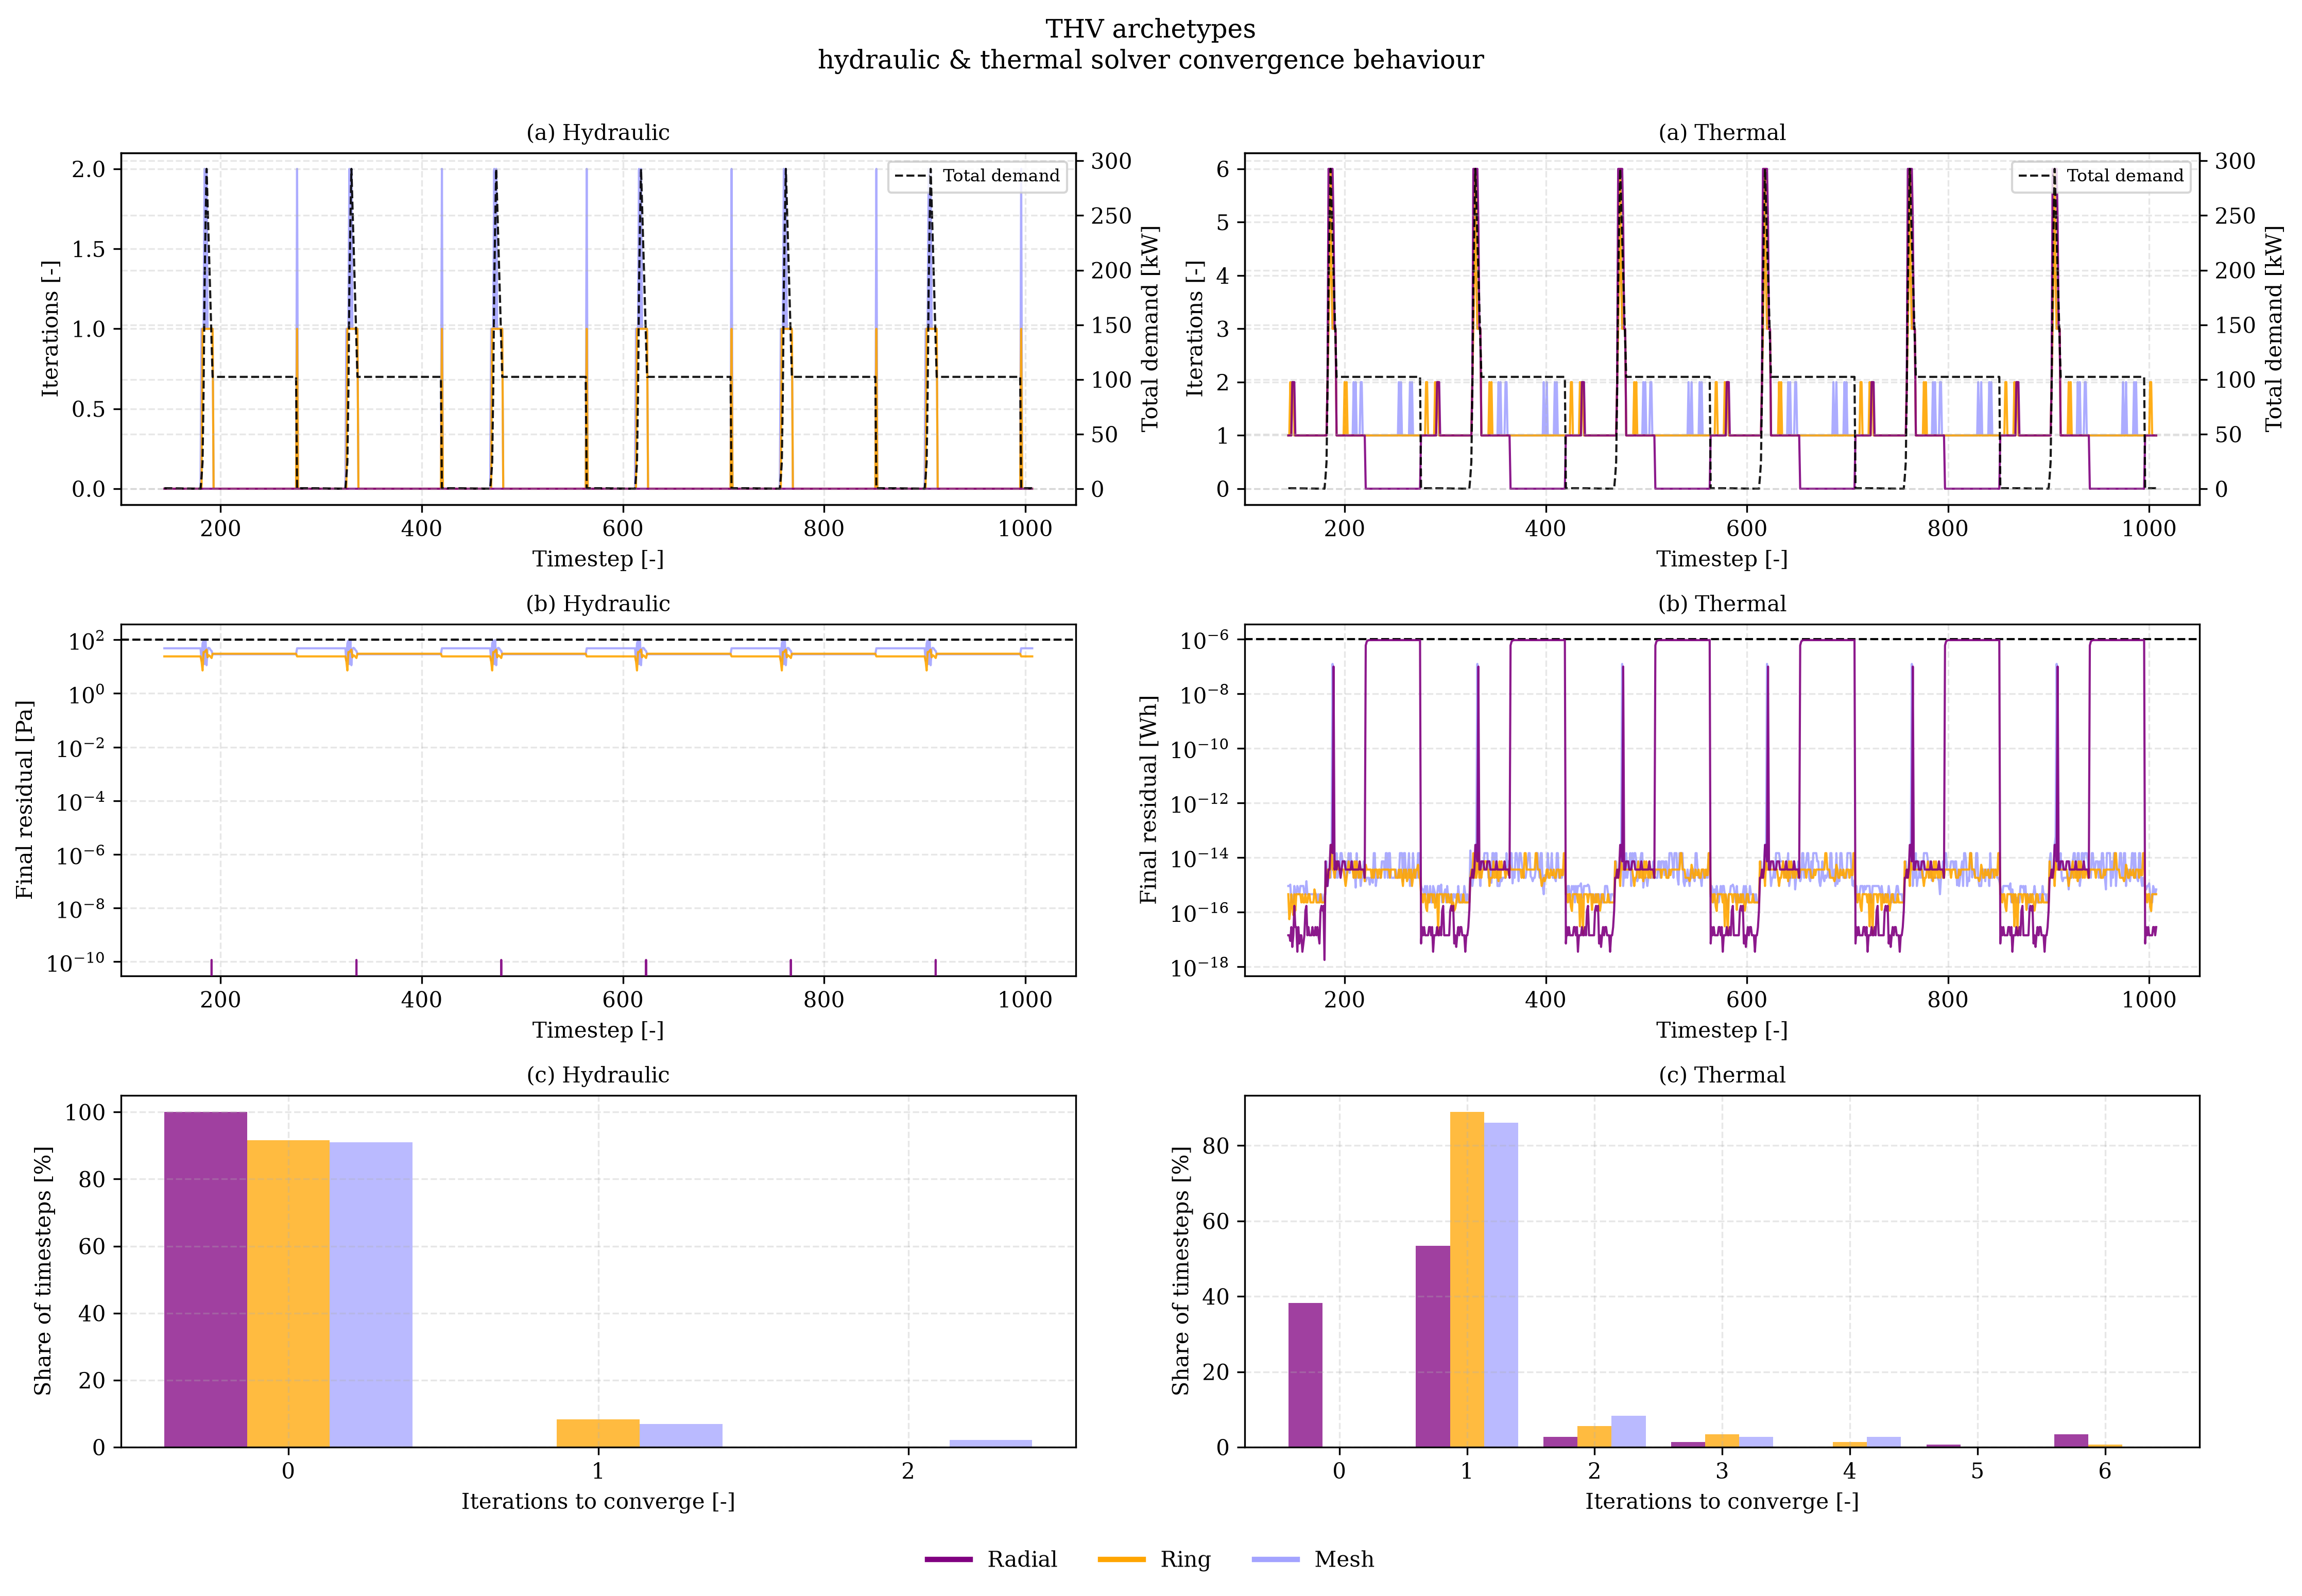

In [12]:
# ---------------------------------------------------------------------------
# THV: hydraulic & thermal solver behaviour
# Row 0: iterations per timestep + demand overlay
# Row 1: final residual per timestep vs threshold
# Row 2: iteration-count distribution (bar chart)
# Single shared legend for the 3 networks, bottom-center of the figure
# ---------------------------------------------------------------------------
from matplotlib.lines import Line2D

THRESHOLD_HYDRAULIC_PA = 1e2
THRESHOLD_THERMAL_K    = 1e-6

COLORS = {"Radial": "purple", "Ring": "orange", "Mesh": "#A3A3FF"}
ZORDER = {"Radial": 3, "Ring": 2, "Mesh": 1}

DOMAIN_CONFIG = {
    "hydraulics": {
        "iter_col": "hydraulics_iterations",
        "resid_col": "hydraulics_final_residual",
        "threshold": THRESHOLD_HYDRAULIC_PA,
        "resid_unit": "Pa",
        "label": "Hydraulic",
    },
    "thermal": {
        "iter_col": "thermal_iterations",
        "resid_col": "thermal_final_residual",
        "threshold": THRESHOLD_THERMAL_K,
        "resid_unit": "Wh",
        "label": "Thermal",
    },
}

# --- helpers for the convergence_traj domain slicing ------------------------
def get_domain_slice(conv, domain, label):
    if "domain" in conv.columns:
        d = conv[conv["domain"] == domain]
        if d.empty:
            print(f"[WARN] no '{domain}' rows in convergence_traj for {label}")
        return d
    else:
        if domain == "hydraulics":
            print(f"[INFO] {label}: 'domain' column missing (old export format) — "
                  f"treating entire sheet as hydraulic data")
            return conv
        else:
            print(f"[WARN] {label}: 'domain' column missing (old export format) — "
                  f"no thermal trajectories available")
            return conv.iloc[0:0]

fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=False)

for col, (domain, cfg) in enumerate(DOMAIN_CONFIG.items()):

    # --- ROW 0: iterations per timestep + total demand overlay -------------
    ax_iter = axes[0, col]
    ax_demand = ax_iter.twinx()

    demand_plotted = False
    for name, net in THV_NETWORKS.items():
        df = net["solver_iteration"]
        if cfg["iter_col"] not in df.columns:
            print(f"[WARN] '{cfg['iter_col']}' missing for {name} ({domain})")
            continue
        ax_iter.plot(df.index, df[cfg["iter_col"]],
                     color=COLORS.get(name), lw=1.0,
                     alpha=0.9, zorder=ZORDER.get(name, 1))
        if not demand_plotted and "Q_demand_tot_W" in df.columns:
            ax_demand.plot(df.index, df["Q_demand_tot_W"] / 1e3,
                           color="black", lw=1.0, alpha=0.9, linestyle="--",
                           label="Total demand", zorder=0)
            demand_plotted = True

    ax_iter.set_ylabel("Iterations [-]")
    ax_demand.set_ylabel("Total demand [kW]", color="black")
    ax_demand.tick_params(axis="y", colors="black")
    ax_iter.set_xlabel("Timestep [-]")
    ax_iter.set_title(f"(a) {cfg['label']}")
    ax_iter.grid(True, alpha=0.3, linestyle="--")
    # only the demand-overlay entry here (network colours go in the shared legend)
    h2, l2 = ax_demand.get_legend_handles_labels()
    if h2:
        ax_iter.legend(h2, l2, loc="upper right", fontsize=8)

    # --- ROW 1: final residual vs threshold ---------------------------------
    ax_res = axes[1, col]
    for name, net in THV_NETWORKS.items():
        df = net["solver_iteration"]
        if cfg["resid_col"] not in df.columns:
            print(f"[WARN] '{cfg['resid_col']}' missing for {name} ({domain})")
            continue
        ax_res.semilogy(df.index, df[cfg["resid_col"]],
                         color=COLORS.get(name), lw=1.0,
                         alpha=0.9, zorder=ZORDER.get(name, 1))

    if cfg["threshold"] is not None:
        ax_res.axhline(cfg["threshold"], color="black", linestyle="--", lw=1.0,
                       label=f"Threshold ({cfg['threshold']:.0e} {cfg['resid_unit']})")

    ax_res.set_xlabel("Timestep [-]")
    ax_res.set_ylabel(f"Final residual [{cfg['resid_unit']}]")
    ax_res.set_title(f"(b) {cfg['label']}")
    ax_res.grid(True, which="both", alpha=0.3, linestyle="--")

    # --- ROW 2: iteration-count distribution (bar chart) --------------------
    ax_hist = axes[2, col]
    n_networks = len(THV_NETWORKS)
    bar_width = 0.8 / n_networks
    all_max_iter = 0
    per_network_counts = {}

    for name, net in THV_NETWORKS.items():
        df = net["solver_iteration"]
        if cfg["iter_col"] not in df.columns:
            continue
        counts = df[cfg["iter_col"]].dropna().astype(int).value_counts(normalize=True).sort_index() * 100
        per_network_counts[name] = counts
        all_max_iter = max(all_max_iter, counts.index.max())

    x_range = np.arange(0, all_max_iter + 1)
    for i, (name, counts) in enumerate(per_network_counts.items()):
        y = counts.reindex(x_range, fill_value=0.0)
        offset = (i - (n_networks - 1) / 2) * bar_width
        ax_hist.bar(x_range + offset, y.values, width=bar_width,
                    color=COLORS.get(name), alpha=0.75)

    ax_hist.set_xlabel("Iterations to converge [-]")
    ax_hist.set_ylabel("Share of timesteps [%]")
    ax_hist.set_title(f"(c) {cfg['label']}")
    ax_hist.set_xticks(x_range)
    ax_hist.grid(True, axis="y", alpha=0.3, linestyle="--")


network_handles = [Line2D([0], [0], color=COLORS[name], lw=2.5, label=name)
                    for name in THV_NETWORKS.keys()]
fig.legend(handles=network_handles, loc="lower center",
           ncol=len(network_handles), fontsize=10, frameon=False,
           bbox_to_anchor=(0.5, -0.02))

fig.suptitle("THV archetypes\nhydraulic & thermal solver convergence behaviour",
             fontsize=12, y=1.00)
fig.tight_layout(rect=[0, 0.015, 1, 1])

save_fig(fig, "THV_solver_convergence")
plt.show()